# CIE 2 – Machine Learning Activity 1: Dataset Preparation

**Student:** ___SANAT RAMTEKE_______________  
**Class/Division:** _____AIDS(C)_______________  
**Roll No.:** _____AD3307_______________

## Objective
To inspect a tabular dataset, identify data-quality issues, perform basic EDA and prepare a cleaned dataset for future machine-learning work.

## Dataset
**Student Performance Dataset** from the UCI Machine Learning Repository.  
Source: https://archive.ics.uci.edu/dataset/320/student+performance

This notebook uses the `student-mat.csv` file. Download it from the UCI dataset page, extract the ZIP file, and upload `student-mat.csv` to this notebook when prompted.


## Step 1–2: Load and inspect the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# In Google Colab, this opens a file-upload prompt.
from google.colab import files
uploaded = files.upload()

file_name = next(iter(uploaded))
df_original = pd.read_csv(file_name, sep=';')

print("Dataset shape (rows, columns):", df_original.shape)
print("\nFirst 5 rows:")
display(df_original.head())

print("\nLast 5 rows:")
display(df_original.tail())

print("\nColumn names:")
print(df_original.columns.tolist())

print("\nData types:")
print(df_original.dtypes)


Saving student-mat.csv to student-mat.csv
Dataset shape (rows, columns): (395, 33)

First 5 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10



Last 5 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10
394,MS,M,19,U,LE3,T,1,1,other,at_home,...,3,2,3,3,3,5,5,8,9,9



Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data types:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1            

## Step 3: Data types and basic statistics

In [2]:
numeric_cols = df_original.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_original.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", numeric_cols)
print("\nCategorical columns:", categorical_cols)

print("\nSummary statistics for numerical columns:")
display(df_original[numeric_cols].describe())

print("\nFrequency counts for a categorical column (school):")
display(df_original['school'].value_counts(dropna=False))

print("\nPossible target for a future prediction task: G3 (final grade).")
print("This activity does not require training a prediction model.")


Numerical columns: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Categorical columns: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Summary statistics for numerical columns:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000



Frequency counts for a categorical column (school):


,count
school,
GP,349
MS,46



Possible target for a future prediction task: G3 (final grade).
This activity does not require training a prediction model.


## Step 4: Identify missing values

In [3]:
missing_count = df_original.isnull().sum()
missing_percent = (missing_count / len(df_original) * 100).round(2)

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': missing_percent
})
display(missing_summary)

print("Total missing cells:", int(df_original.isnull().sum().sum()))


,Missing Count,Missing Percentage
school,0,0.0
sex,0,0.0
age,0,0.0
address,0,0.0
famsize,0,0.0
Pstatus,0,0.0
Medu,0,0.0
Fedu,0,0.0
Mjob,0,0.0
Fjob,0,0.0


Total missing cells: 0


## Step 5: Handle missing values

In [ ]:
# Keep the original unchanged and work on a separate copy.
df = df_original.copy()

# Impute numerical columns with their median and categorical columns with their mode,
# but only if a column actually contains missing values.
for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            mode_values = df[col].mode(dropna=True)
            if not mode_values.empty:
                df[col] = df[col].fillna(mode_values.iloc[0])

print("Missing values after handling:")
display(df.isnull().sum().to_frame(name='Remaining Missing Values'))


## Step 6: Check duplicates and consistency

In [7]:
# Ensure df is defined even if the previous cell was skipped
if 'df' not in locals() and 'df_original' in locals():
    df = df_original.copy()

duplicate_count = int(df.duplicated().sum())
print("Duplicate rows found:", duplicate_count)

# Remove exact duplicate rows, if any.
df_original = df.drop_duplicates().copy()

# Remove accidental leading/trailing spaces from text columns.
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype('string').str.strip()

print("Shape after duplicate check:", df.shape)
print("Duplicate rows remaining:", int(df.duplicated().sum()))

Duplicate rows found: 0
Shape after duplicate check: (395, 33)
Duplicate rows remaining: 0


## Step 7: Basic exploratory data analysis (EDA)

Numerical summary:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


School frequency:


,count
school,
GP,349
MS,46


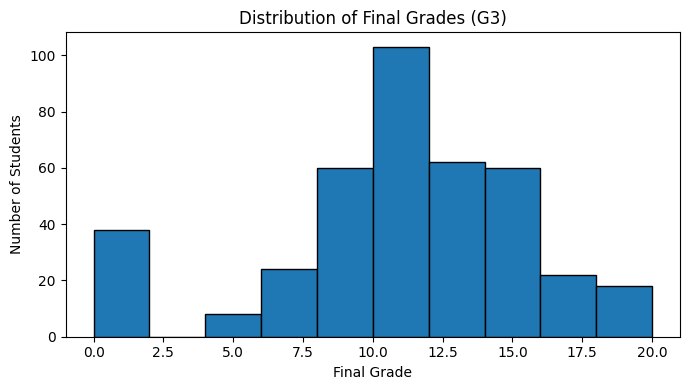

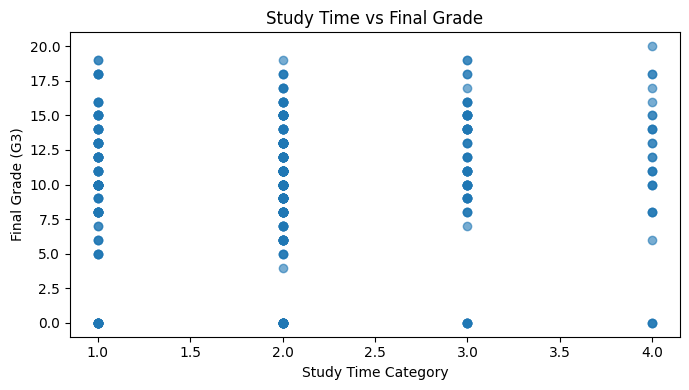

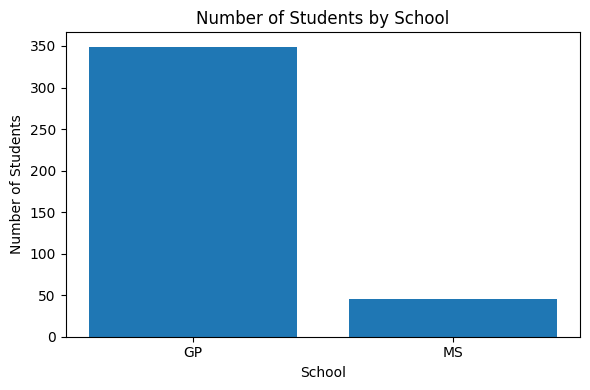

In [8]:
print("Numerical summary:")
display(df.select_dtypes(include=np.number).describe())

print("School frequency:")
display(df['school'].value_counts())

# Visualisation 1: Distribution of final grade
plt.figure(figsize=(7, 4))
plt.hist(df['G3'], bins=10, edgecolor='black')
plt.title('Distribution of Final Grades (G3)')
plt.xlabel('Final Grade')
plt.ylabel('Number of Students')
plt.tight_layout()
plt.show()

# Visualisation 2: Study time versus final grade
plt.figure(figsize=(7, 4))
plt.scatter(df['studytime'], df['G3'], alpha=0.6)
plt.title('Study Time vs Final Grade')
plt.xlabel('Study Time Category')
plt.ylabel('Final Grade (G3)')
plt.tight_layout()
plt.show()

# Visualisation 3: Count of students by school
school_counts = df['school'].value_counts()
plt.figure(figsize=(6, 4))
plt.bar(school_counts.index.astype(str), school_counts.values)
plt.title('Number of Students by School')
plt.xlabel('School')
plt.ylabel('Number of Students')
plt.tight_layout()
plt.show()


### EDA observations

After running the notebook, write 2–3 observations based on the graphs shown above. For example, describe the shape of the G3 grade distribution and whether the scatter plot suggests a clear or weak pattern. Use the actual graphs and avoid claiming a result that you did not observe.


## Step 8: Encode categorical features

In [9]:
# One-hot encode nominal categorical columns.
# drop_first=True avoids keeping one redundant category column for each feature.
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)

print("Original shape after cleaning:", df.shape)
print("Shape after one-hot encoding:", df_encoded.shape)
display(df_encoded.head())

print("Explanation: text categories are represented by 0/1 indicator columns after one-hot encoding.")


Original shape after cleaning: (395, 33)
Shape after one-hot encoding: (395, 42)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,0,1,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,1,0,0,1,1,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,...,0,0,0,1,1,0,1,1,0,0


Explanation: text categories are represented by 0/1 indicator columns after one-hot encoding.


## Step 9: Scale numerical input features where appropriate

In [10]:
# Standardise numerical columns, excluding the target G3.
# This is a preparation demonstration; no model is trained in Activity 1.
numeric_to_scale = df_encoded.select_dtypes(include=np.number).columns.tolist()
if 'G3' in numeric_to_scale:
    numeric_to_scale.remove('G3')

df_prepared = df_encoded.copy()
if numeric_to_scale:
    scaler = StandardScaler()
    df_prepared[numeric_to_scale] = scaler.fit_transform(df_prepared[numeric_to_scale])

print("Scaling method: Standardisation (mean 0, standard deviation 1).")
print("Target column G3 was not scaled.")
display(df_prepared.head())


Scaling method: Standardisation (mean 0, standard deviation 1).
Target column G3 was not scaled.


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,1.023046,1.143856,1.360371,0.792251,-0.042286,-0.449944,0.062194,-0.236010,0.801479,-0.540699,...,0.668496,-0.296908,2.597133,-1.257656,-0.919671,-1.017881,0.507899,0.23094,-2.232677,-0.708450
1,0.238380,-1.600009,-1.399970,-0.643249,-0.042286,-0.449944,1.178860,-0.236010,-0.097908,-0.540699,...,-1.495896,-0.296908,-0.385040,0.795130,-0.919671,-1.017881,-1.968894,0.23094,0.447893,-0.708450
2,-1.330954,-1.600009,-1.399970,-0.643249,-0.042286,3.589323,0.062194,-0.236010,-0.997295,0.583385,...,0.668496,-0.296908,2.597133,-1.257656,1.087346,-1.017881,0.507899,0.23094,0.447893,-0.708450
3,-1.330954,1.143856,-0.479857,-0.643249,1.150779,-0.449944,-1.054472,-1.238419,-0.997295,-0.540699,...,0.668496,-0.296908,-0.385040,0.795130,1.087346,0.982433,0.507899,0.23094,0.447893,1.411533
4,-0.546287,0.229234,0.440257,-0.643249,-0.042286,-0.449944,0.062194,-0.236010,-0.997295,-0.540699,...,-1.495896,-0.296908,-0.385040,0.795130,1.087346,-1.017881,0.507899,0.23094,-2.232677,-0.708450


## Step 10: Verify and save the prepared dataset

In [11]:
print("Final shape:", df_prepared.shape)
print("Total missing values:", int(df_prepared.isnull().sum().sum()))
print("Duplicate rows:", int(df_prepared.duplicated().sum()))

output_file = 'student_performance_prepared.csv'
df_prepared.to_csv(output_file, index=False)
print("Saved prepared dataset as:", output_file)

display(df_prepared.head())

# Download the prepared CSV in Google Colab.
files.download(output_file)


Final shape: (395, 42)
Total missing values: 0
Duplicate rows: 0
Saved prepared dataset as: student_performance_prepared.csv


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,1.023046,1.143856,1.360371,0.792251,-0.042286,-0.449944,0.062194,-0.236010,0.801479,-0.540699,...,0.668496,-0.296908,2.597133,-1.257656,-0.919671,-1.017881,0.507899,0.23094,-2.232677,-0.708450
1,0.238380,-1.600009,-1.399970,-0.643249,-0.042286,-0.449944,1.178860,-0.236010,-0.097908,-0.540699,...,-1.495896,-0.296908,-0.385040,0.795130,-0.919671,-1.017881,-1.968894,0.23094,0.447893,-0.708450
2,-1.330954,-1.600009,-1.399970,-0.643249,-0.042286,3.589323,0.062194,-0.236010,-0.997295,0.583385,...,0.668496,-0.296908,2.597133,-1.257656,1.087346,-1.017881,0.507899,0.23094,0.447893,-0.708450
3,-1.330954,1.143856,-0.479857,-0.643249,1.150779,-0.449944,-1.054472,-1.238419,-0.997295,-0.540699,...,0.668496,-0.296908,-0.385040,0.795130,1.087346,0.982433,0.507899,0.23094,0.447893,1.411533
4,-0.546287,0.229234,0.440257,-0.643249,-0.042286,-0.449944,0.062194,-0.236010,-0.997295,-0.540699,...,-1.495896,-0.296908,-0.385040,0.795130,1.087346,-1.017881,0.507899,0.23094,-2.232677,-0.708450


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
The Student Performance dataset was loaded and inspected. Numerical and categorical columns were identified, missing values and duplicate rows were checked, and basic visualisations were created. Categorical features were converted using one-hot encoding, and numerical input features were standardised while the possible target column G3 was left unscaled. The prepared dataset was saved separately as `student_performance_prepared.csv`. Fill in or adjust this conclusion after running the notebook and checking the actual outputs.
